# Funnel Chart

**Family:** Flow &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Flow:* Show the volume or intensity of movement between states, stages, or places.

## Design purpose

A sequence of centered bars, one per stage of a process, each no larger than the one before. It shows how many items remain at each step and where the largest drop-offs occur.

## When to use

- Show a sales or marketing conversion pipeline (visit → sign-up → purchase)
- Show applicant screening pipelines (loan applications, hiring, trial recruitment)
- Find the stage with the biggest loss

## Avoid when

- Stages are not strictly sequential or subsets of each other
- Values can increase between stages (use a bar chart or waterfall)

## Alternatives

- Horizontal bar chart with conversion %
- Sankey diagram (to show where drop-offs go)

## Design tips

- Label each stage with both the count and the conversion from the previous step
- Use one color: the stages are the same measure, not different categories

## Example

A B2B sales pipeline for one year, from inbound leads to closed-won deals.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
pio.templates["vizlib"] = go.layout.Template(layout=dict(
    colorway=PALETTE, font=dict(family="Helvetica, Arial, sans-serif", size=13, color="#0b0b0b"),
    paper_bgcolor="#fcfcfb", plot_bgcolor="#fcfcfb", title=dict(x=0.02, xanchor="left"),
    xaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
    yaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
))
pio.templates.default = "plotly_white+vizlib"
pio.renderers.default = "plotly_mimetype+notebook_connected"

### Data

In [2]:
stages = pd.Series({"Leads": 2400, "Qualified": 1150, "Demo held": 640,
                    "Proposal sent": 410, "Closed-won": 230})
stages.to_frame("deals").assign(step_conversion=(stages / stages.shift()).round(2))

,deals,step_conversion
Leads,2400,NaN
Qualified,1150,0.48
Demo held,640,0.56
Proposal sent,410,0.64
Closed-won,230,0.56


### Plot

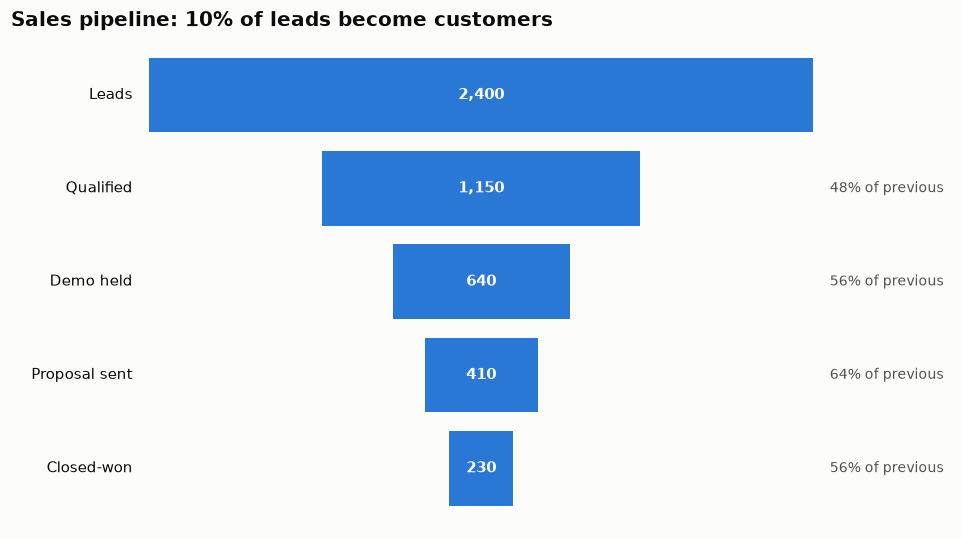

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(stages))[::-1]
ax.barh(y, stages.values, left=-stages.values / 2, color=PALETTE[0], height=0.8)
for yi, (name, v), prev in zip(y, stages.items(), [None] + list(stages.values[:-1])):
    ax.text(0, yi, f"{v:,}", ha="center", va="center", color="white", fontweight="bold")
    ax.text(-stages.max() / 2 - 60, yi, name, ha="right", va="center", fontsize=10)
    if prev:
        ax.text(stages.max() / 2 + 60, yi, f"{v / prev:.0%} of previous", ha="left",
                va="center", fontsize=9, color="#52514e")
ax.set_xlim(-stages.max() / 2 - 500, stages.max() / 2 + 500)
ax.axis("off")
ax.set_title(f"Sales pipeline: {stages.iloc[-1] / stages.iloc[0]:.0%} of leads become customers")
fig.tight_layout()
plt.show()

## How to read it

Bar width is the number of deals still in the pipeline. The biggest loss is at qualification (48% pass); demos and closing each keep 56%.

## The same chart in other libraries

Each version uses the example data above. Pick the library that fits your stack: matplotlib/seaborn for static and print figures, plotly for interactive HTML, Altair for concise declarative specs.

### plotly

In [4]:
import plotly.graph_objects as go
fig = go.Figure(go.Funnel(y=stages.index, x=stages.values, textinfo="value+percent previous",
                          marker=dict(color=PALETTE[0]), connector=dict(fillcolor="#e6e5e1")))
fig.update_layout(title=f"Sales pipeline: {stages.iloc[-1] / stages.iloc[0]:.0%} of leads become customers")
fig.show()

---
Standalone script: [`funnel_chart.py`](funnel_chart.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)